# 🇨🇴 Hurtos en Colombia — Descarga y análisis (datos.gov.co)

**Fuente:** *Reporte Hurto por Modalidades – Policía Nacional (DIJIN)*, publicado en [datos.gov.co](https://www.datos.gov.co) (API Socrata). Según la Policía, el conjunto se actualizó el 20/04/2026.

**Cómo usar este cuaderno:** ejecuta las celdas en orden (`Entorno de ejecución → Ejecutar todo`).

| Sección | Qué hace |
|---|---|
| 1 | Instala/importa librerías |
| 2 | **Configuración** (aquí cambias filtros y opciones) |
| 3 | Funciones de apoyo |
| 4 | Explora los 3 recursos (columnas, filas, fechas) |
| 5 | **Descarga todos los datos** con paginación |
| 6 | Limpieza |
| 7 | Análisis y gráficos |
| 8 | Exportar (CSV / Parquet / Drive) |

> ⚠️ Cada fila puede agrupar varios hechos. Para contar hurtos usa la suma de la columna `cantidad`, **no** el número de filas.

## 1. Librerías

In [ ]:
%pip install -q requests pandas matplotlib tqdm pyarrow

import os, time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy import stats
import numpy as np

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Configuración

- `DESDE`: fecha mínima (`"2026-01-01"`) o `None` para descargar **todo el histórico**.
- `APP_TOKEN`: opcional. Token gratuito de datos.gov.co para tener más cuota de peticiones.
- `GUARDAR_EN_DRIVE`: si es `True`, guarda los archivos en tu Google Drive.

In [ ]:
# Recursos del conjunto "Reporte Hurto por Modalidades - Policía Nacional"
RECURSOS = {
    "9vha-vh9n": "Hurto por modalidades (recurso 1)",
    "6sqw-8cg5": "Hurto por modalidades (recurso 2)",
    "d4fr-sbn2": "Hurto por modalidades (recurso 3)",
}

DESDE = None            # Ejemplo: "2026-01-01"  |  None = todo el histórico
APP_TOKEN = ""          # Opcional (Socrata App Token)
PAGINA = 50_000         # Filas por petición
PAUSA = 0.4             # Segundos entre peticiones (cortesía con el servidor)

GUARDAR_EN_DRIVE = False
CARPETA_DRIVE = "/content/drive/MyDrive/datos_hurtos"
CARPETA_LOCAL = "/content/datos"

BASE = "https://www.datos.gov.co"
HEADERS = {"User-Agent": "Mozilla/5.0 (analisis-datos-abiertos; Colab)"}
if APP_TOKEN:
    HEADERS["X-App-Token"] = APP_TOKEN

os.makedirs(CARPETA_LOCAL, exist_ok=True)

## 3. Funciones de apoyo

In [ ]:
def get(url, params=None, intentos=5):
    """GET con reintentos y pausa creciente."""
    ultimo = None
    for i in range(intentos):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r
            ultimo = f"HTTP {r.status_code}"
        except requests.RequestException as e:
            ultimo = str(e)
        time.sleep(2 * (i + 1))
    raise RuntimeError(f"No se pudo obtener {url}: {ultimo}")


def metadatos(rid):
    return get(f"{BASE}/api/views/{rid}.json").json()


def columnas(meta):
    return [c for c in meta["columns"] if not c["fieldName"].startswith(":")]


def columna_fecha(meta):
    """Detecta la columna de fecha por tipo; si no, por nombre."""
    cols = columnas(meta)
    for c in cols:
        if c.get("dataTypeName") in ("calendar_date", "date", "floating_timestamp"):
            return c["fieldName"]
    for c in cols:
        if "fecha" in c["fieldName"].lower():
            return c["fieldName"]
    return None


def cuenta(rid, where=None):
    p = {"$select": "count(*)"}
    if where:
        p["$where"] = where
    return int(get(f"{BASE}/resource/{rid}.json", p).json()[0]["count"])

## 4. Explorar los recursos
Muestra cuántas filas tiene cada recurso, sus columnas y qué años cubre. Así sabes cuál contiene datos de 2026.

In [ ]:
resumen = []
for rid in RECURSOS:
    m = metadatos(rid)
    fcol = columna_fecha(m)
    desde = hasta = None
    if fcol:
        r = get(f"{BASE}/resource/{rid}.json",
                {"$select": f"min({fcol}) as desde, max({fcol}) as hasta"}).json()[0]
        desde, hasta = r.get("desde"), r.get("hasta")
    resumen.append({
        "recurso": rid,
        "nombre": m.get("name"),
        "filas": cuenta(rid),
        "col_fecha": fcol,
        "desde": desde,
        "hasta": hasta,
        "columnas": [c["fieldName"] for c in columnas(m)],
    })

resumen_df = pd.DataFrame(resumen)
resumen_df

,recurso,nombre,filas,col_fecha,desde,hasta,columnas
0,9vha-vh9n,Reporte Hurto por Modalidades Policía Nacional,656635,fecha_hecho,01/01/2010,31/12/2025,"[departamento, municipio, codigo_dane, armas_m..."
1,6sqw-8cg5,Reporte Hurto por Modalidades Policía Nacional,653384,fecha_hecho,01/01/2010,31/12/2025,"[departamento, municipio, codigo_dane, armas_m..."
2,d4fr-sbn2,Reporte Hurto por Modalidades Policía Nacional,44423,fecha_hecho,01/01/2010,31/12/2025,"[departamento, municipio, codigo_dane, armas_m..."


## 5. Descargar TODOS los datos
Descarga cada recurso por páginas de 50.000 filas, guarda un CSV por recurso y los une en un solo `DataFrame` (`df`).

In [ ]:
def descargar_recurso(rid, desde=None):
    m = metadatos(rid)
    fcol = columna_fecha(m)
    where = f"{fcol} >= '{desde}T00:00:00.000'" if (desde and fcol) else None
    total = cuenta(rid, where)
    partes, offset = [], 0

    with tqdm(total=total, desc=rid, unit="filas") as barra:
        while offset < total:
            p = {"$limit": PAGINA, "$offset": offset, "$order": ":id"}  # orden estable
            if where:
                p["$where"] = where
            filas = get(f"{BASE}/resource/{rid}.json", p).json()
            if not filas:
                break
            partes.append(pd.DataFrame(filas))
            offset += len(filas)
            barra.update(len(filas))
            time.sleep(PAUSA)

    df_r = pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()
    df_r["recurso"] = rid
    ruta = f"{CARPETA_LOCAL}/hurtos_{rid}.csv"
    df_r.to_csv(ruta, index=False, encoding="utf-8-sig")
    print(f"   -> {ruta}  ({len(df_r):,} filas)")
    return df_r


descargas = [descargar_recurso(rid, DESDE) for rid in RECURSOS]
df = pd.concat([d for d in descargas if not d.empty], ignore_index=True)

print(f"\nTOTAL: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.head()

9vha-vh9n:   0%|          | 0/656635 [00:00<?, ?filas/s]

   -> /content/datos/hurtos_9vha-vh9n.csv  (656,635 filas)


6sqw-8cg5:   0%|          | 0/653384 [00:00<?, ?filas/s]

   -> /content/datos/hurtos_6sqw-8cg5.csv  (653,384 filas)


d4fr-sbn2:   0%|          | 0/44423 [00:00<?, ?filas/s]

   -> /content/datos/hurtos_d4fr-sbn2.csv  (44,423 filas)

TOTAL: 1,354,442 filas x 10 columnas


,departamento,municipio,codigo_dane,armas_medios,fecha_hecho,genero,grupo_etario,tipo_de_hurto,cantidad,recurso
0,ATLÁNTICO,Barranquilla (CT),08001000,NO REPORTADO,05/03/2014,FEMENINO,ADULTOS,ARTÍCULO 239. HURTO AUTOMOTORES,1,9vha-vh9n
1,META,Villavicencio (CT),50001000,NO REPORTADO,14/02/2014,FEMENINO,ADULTOS,ARTÍCULO 239. HURTO AUTOMOTORES,1,9vha-vh9n
2,NORTE DE SANTANDER,Los Patios,54405000,NO REPORTADO,21/02/2014,MASCULINO,ADULTOS,ARTÍCULO 239. HURTO MOTOCICLETAS,1,9vha-vh9n
3,ANTIOQUIA,Amagá,05030000,NO REPORTADO,03/01/2014,MASCULINO,ADULTOS,ARTÍCULO 239. HURTO MOTOCICLETAS,1,9vha-vh9n
4,META,Villavicencio (CT),50001000,NO REPORTADO,22/02/2014,MASCULINO,ADULTOS,ARTÍCULO 239. HURTO AUTOMOTORES,1,9vha-vh9n


## 6. Limpieza
Convierte fechas y cantidades, normaliza texto y crea columnas `anio` y `mes`.

In [ ]:
df = df.copy()

# Fecha
COL_FECHA = next((c for c in df.columns if "fecha" in c.lower()), None)
if COL_FECHA:
    df[COL_FECHA] = pd.to_datetime(df[COL_FECHA], errors="coerce")
    df["anio"] = df[COL_FECHA].dt.year
    df["mes"] = df[COL_FECHA].dt.to_period("M").dt.to_timestamp()

# Cantidad (si no existe, cada fila cuenta como 1 hecho)
if "cantidad" in df.columns:
    df["cantidad"] = pd.to_numeric(df["cantidad"], errors="coerce").fillna(1)
else:
    df["cantidad"] = 1

# Texto en mayúsculas y sin espacios sobrantes
for c in df.select_dtypes(include="object").columns:
    if c != "recurso":
        df[c] = df[c].astype("string").str.strip().str.upper()

# Columnas categóricas útiles para el análisis (se detectan por nombre)
CLAVES = ("departamento", "municipio", "modalidad", "arma", "genero", "tipo", "conducta", "zona", "clase")
CATEGORICAS = [c for c in df.columns if any(k in c.lower() for k in CLAVES)]

print("Columna de fecha :", COL_FECHA)
print("Categóricas      :", CATEGORICAS)
print(f"Total de hechos (suma de 'cantidad'): {int(df['cantidad'].sum()):,}")
df.info()

Columna de fecha : fecha_hecho
Categóricas      : ['departamento', 'municipio', 'armas_medios', 'genero', 'tipo_de_hurto']
Total de hechos (suma de 'cantidad'): 1,354,442
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1354442 entries, 0 to 1354441
Data columns (total 12 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   departamento   1354442 non-null  string        
 1   municipio      1354441 non-null  string        
 2   codigo_dane    1354442 non-null  string        
 3   armas_medios   1354442 non-null  string        
 4   fecha_hecho    539083 non-null   datetime64[ns]
 5   genero         766507 non-null   string        
 6   grupo_etario   1295759 non-null  string        
 7   tipo_de_hurto  1354442 non-null  string        
 8   cantidad       1354442 non-null  int64         
 9   recurso        1354442 non-null  object        
 10  anio           539083 non-null   float64       
 11  mes            539083 

## 7. Análisis

### 7.1 Calidad de datos

In [ ]:
nulos = df.isna().mean().mul(100).round(2).sort_values(ascending=False).rename("% nulos")
nulos.to_frame()

,% nulos
mes,60.20
anio,60.20
fecha_hecho,60.20
genero,43.41
grupo_etario,4.33
codigo_dane,0.00
municipio,0.00
departamento,0.00
armas_medios,0.00
tipo_de_hurto,0.00


### 7.2 Hechos por año

,hechos
anio,
2010.0,14418
2011.0,19026
2012.0,22251
2013.0,23142
2014.0,22861
2015.0,24287
2016.0,26180
2017.0,42660
2018.0,44136


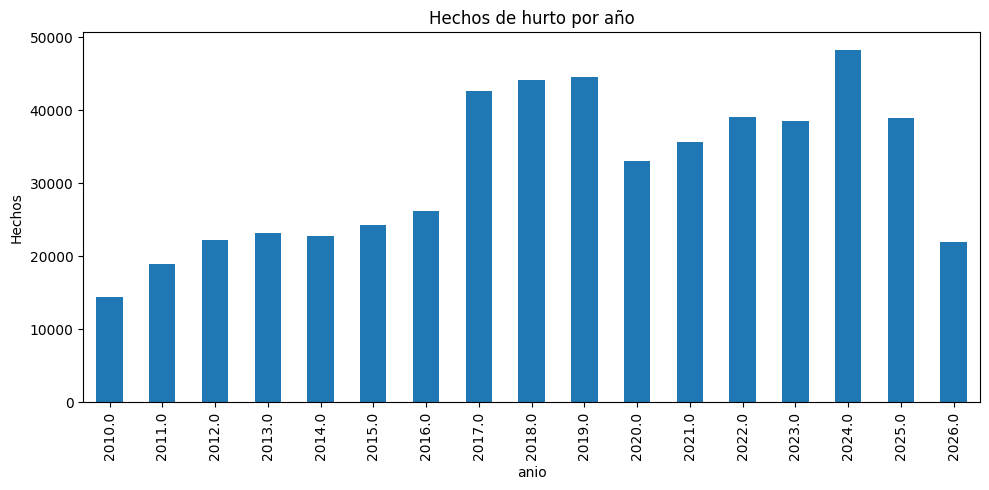

In [ ]:
if "anio" in df.columns:
    por_anio = df.groupby("anio")["cantidad"].sum().astype(int)
    display(por_anio.to_frame("hechos"))
    por_anio.plot.bar(title="Hechos de hurto por año", ylabel="Hechos")
    plt.tight_layout(); plt.show()
else:
    print("No se detectó columna de fecha.")

### 7.3 Serie mensual

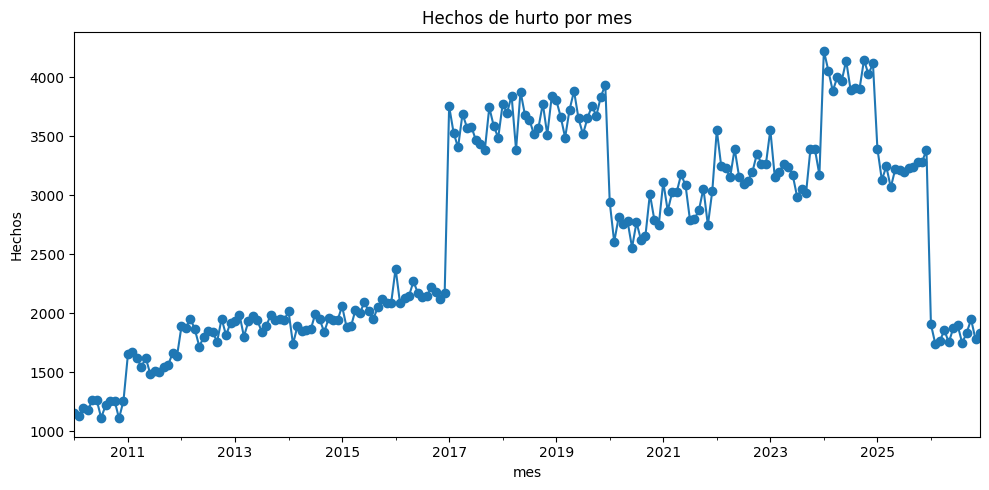

In [ ]:
if "mes" in df.columns:
    mensual = df.groupby("mes")["cantidad"].sum()
    mensual.plot(marker="o", title="Hechos de hurto por mes", ylabel="Hechos")
    plt.tight_layout(); plt.show()

### 7.4 Top 15 por cada variable categórica


=== Top 15 por departamento ===


,hechos
departamento,
BOGOTA,291709
ANTIOQUIA,233474
VALLE,165505
ATLÁNTICO,61526
CUNDINAMARCA,54935
CAUCA,49812
SANTANDER,49691
META,40790
HUILA,38403


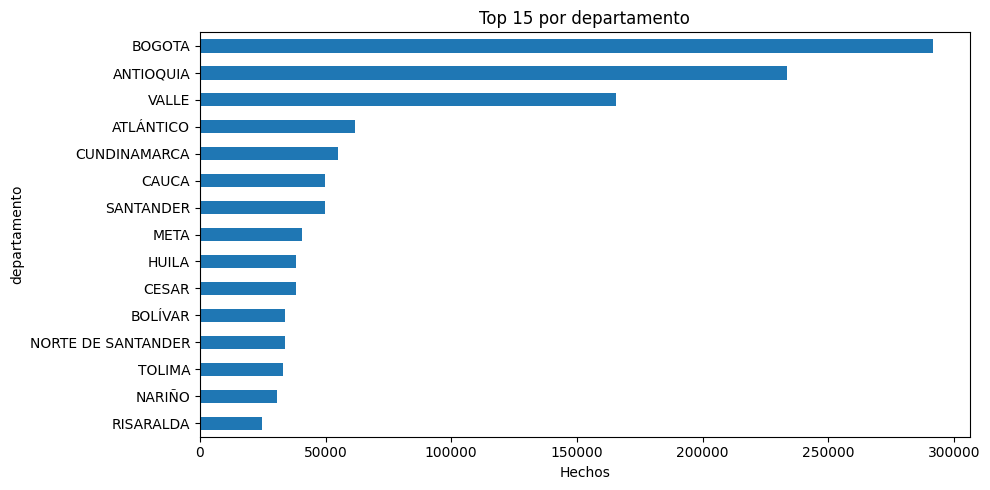


=== Top 15 por municipio ===


,hechos
municipio,
BOGOTÁ D.C. (CT),291709
MEDELLÍN (CT),144795
CALI (CT),113645
BARRANQUILLA (CT),37989
VILLAVICENCIO (CT),25243
POPAYÁN (CT),23578
CARTAGENA (CT),21345
CÚCUTA (CT),20828
BUCARAMANGA (CT),20049


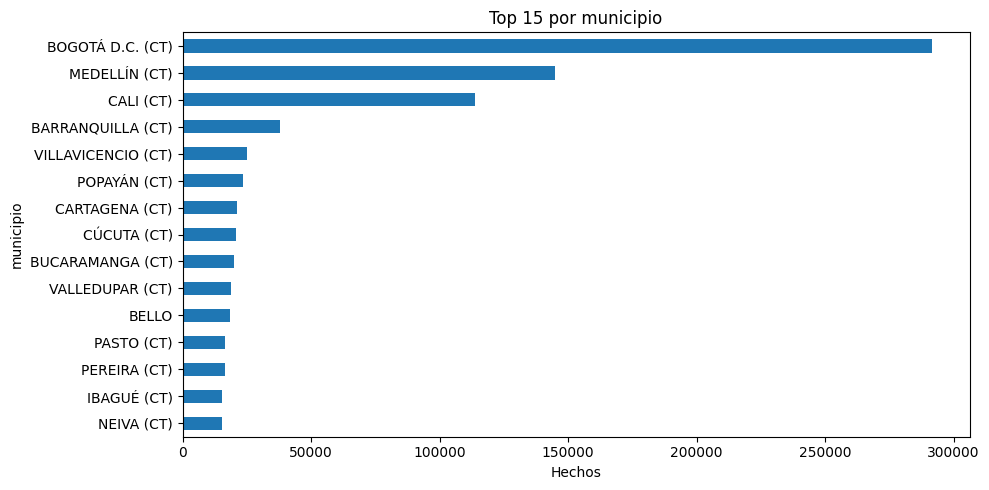


=== Top 15 por armas_medios ===


,hechos
armas_medios,
SIN EMPLEO DE ARMAS,655202
ARMA DE FUEGO,274849
LLAVE MAESTRA,231477
CONTUNDENTES,84285
PALANCAS,40708
ARMA BLANCA / CORTOPUNZANTE,35485
NO REPORTADO,24880
ESCOPOLAMINA,4106
CORTANTES,2718


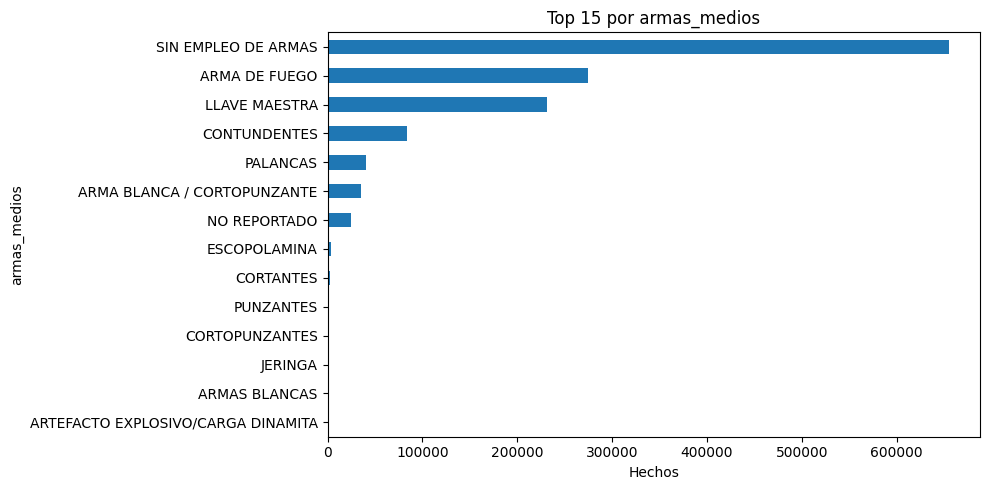


=== Top 15 por genero ===


,hechos
genero,
MASCULINO,602048
FEMENINO,164377
NO REPORTA,82


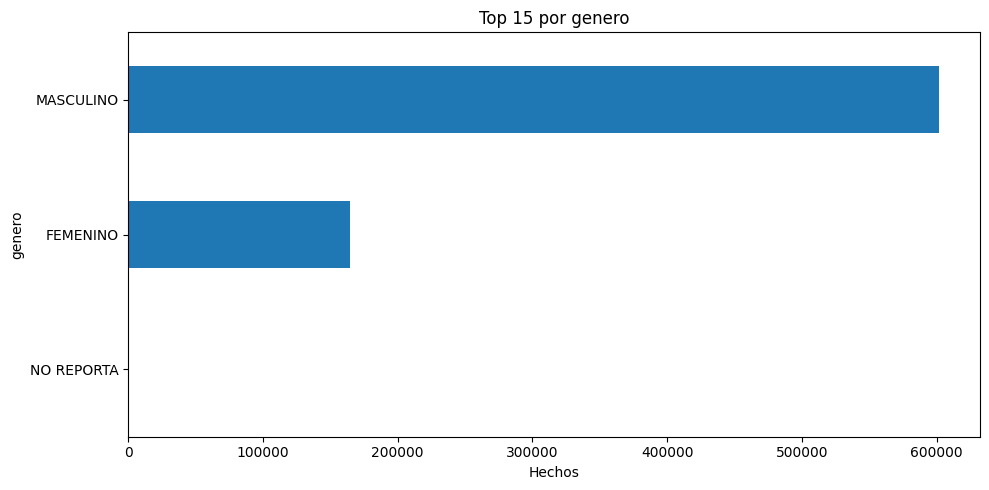


=== Top 15 por tipo_de_hurto ===


,hechos
tipo_de_hurto,
ARTÍCULO 239. HURTO ENTIDADES COMERCIALES,583312
ARTÍCULO 239. HURTO MOTOCICLETAS,497736
ARTÍCULO 239. HURTO AUTOMOTORES,158899
ARTÍCULO 239. HURTO RESIDENCIAS,70072
HURTO ABIGEATO,37775
HURTO PIRATERÍA TERRESTRE,4858
HURTO ENTIDADES FINANCIERAS,1790


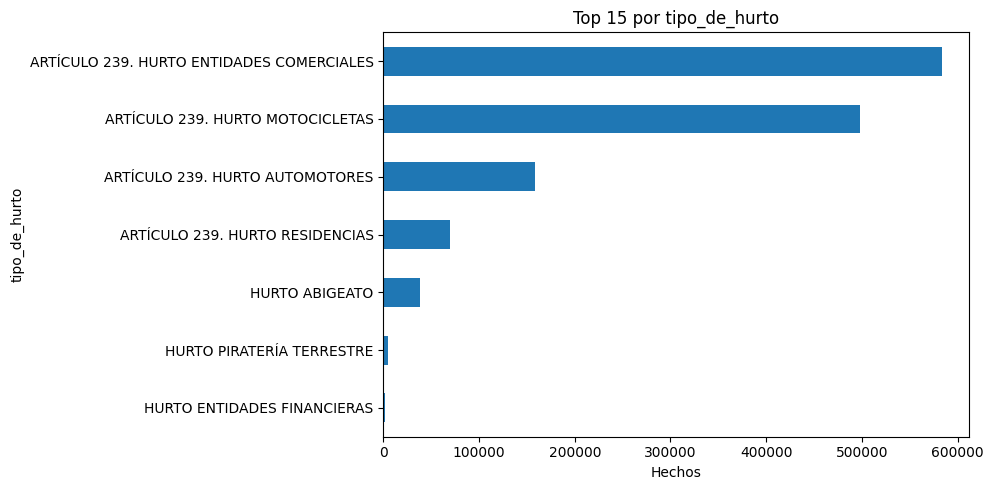

In [ ]:
for c in CATEGORICAS:
    top = df.groupby(c)["cantidad"].sum().sort_values(ascending=False).head(15)
    if top.empty:
        continue
    print(f"\n=== Top 15 por {c} ===")
    display(top.astype(int).to_frame("hechos"))
    top.sort_values().plot.barh(title=f"Top 15 por {c}")
    plt.xlabel("Hechos"); plt.tight_layout(); plt.show()

### 7.5 Solo 2026

In [ ]:
if "anio" in df.columns:
    d26 = df[df["anio"] == 2026]
    print(f"2026: {len(d26):,} filas | {int(d26['cantidad'].sum()):,} hechos")
    if not d26.empty:
        display(d26.groupby("mes")["cantidad"].sum().astype(int).to_frame("hechos"))
    else:
        print("Este conjunto no trae registros de 2026 (prueba con otro recurso o revisa la sección 4).")

2026: 21,947 filas | 21,947 hechos


,hechos
mes,
2026-01-01,1908
2026-02-01,1739
2026-03-01,1764
2026-04-01,1860
2026-05-01,1754
2026-06-01,1874
2026-07-01,1899
2026-08-01,1750
2026-09-01,1834


### 7.6 Enfoque regional (cambia `DEPTO`)

CAUCA: 49,812 filas | 49,812 hechos


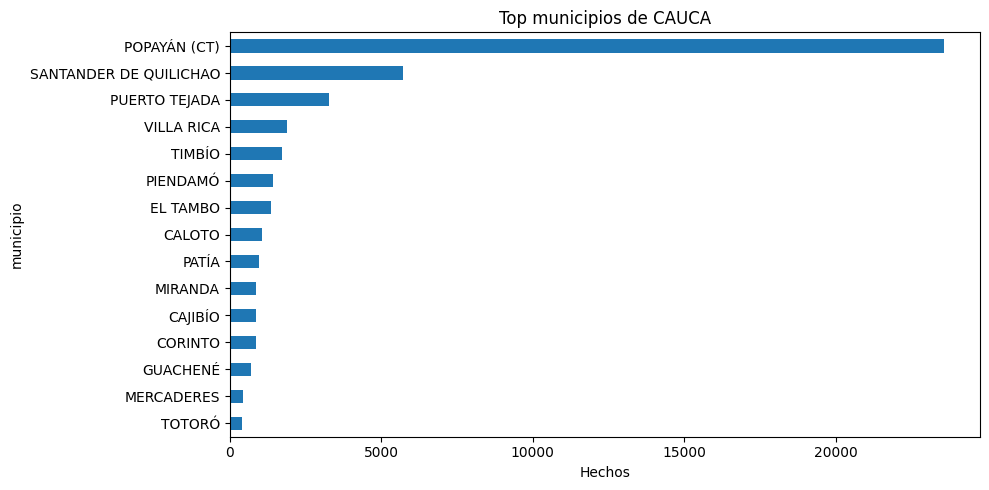

In [ ]:
DEPTO = "CAUCA"
col_depto = next((c for c in df.columns if "departamento" in c.lower()), None)
if col_depto:
    dd = df[df[col_depto].str.contains(DEPTO, na=False)]
    print(f"{DEPTO}: {len(dd):,} filas | {int(dd['cantidad'].sum()):,} hechos")
    col_mun = next((c for c in df.columns if "municipio" in c.lower()), None)
    if col_mun and not dd.empty:
        dd.groupby(col_mun)["cantidad"].sum().sort_values(ascending=False).head(15) \
          .sort_values().plot.barh(title=f"Top municipios de {DEPTO}")
        plt.xlabel("Hechos"); plt.tight_layout(); plt.show()
else:
    print("No se encontró columna de departamento.")

## 9. Modelo de Poisson (preguntas 7, 8 y 10 del informe)

**Experimento ε₁:** observar una semana en un municipio y contar los hurtos.
**Variable:** X = número de hurtos en una semana ~ Poisson(λ), con λ estimado como la media semanal real.

Se usa la suma de `cantidad` (no el número de filas) y solo los registros con `fecha_hecho`.
Las semanas sin hurtos se rellenan con 0 para no sesgar λ hacia arriba.

> Consejo: si λ sale muy grande (p. ej. > 50), filtra por una modalidad (`TIPO`) para tener un conteo más manejable, parecido al λ = 12 del informe.

Municipio: POPAYÁN (CT) | Tipo: TODOS | Año 2025
Semanas: 52 | Total hechos: 723
λ (media semanal) = 13.90 | s² = 224.83 | s²/x̄ = 16.17
⚠️ Sobredispersión: la varianza es bastante mayor que la media; Poisson subestima los extremos (ver conclusiones del informe).


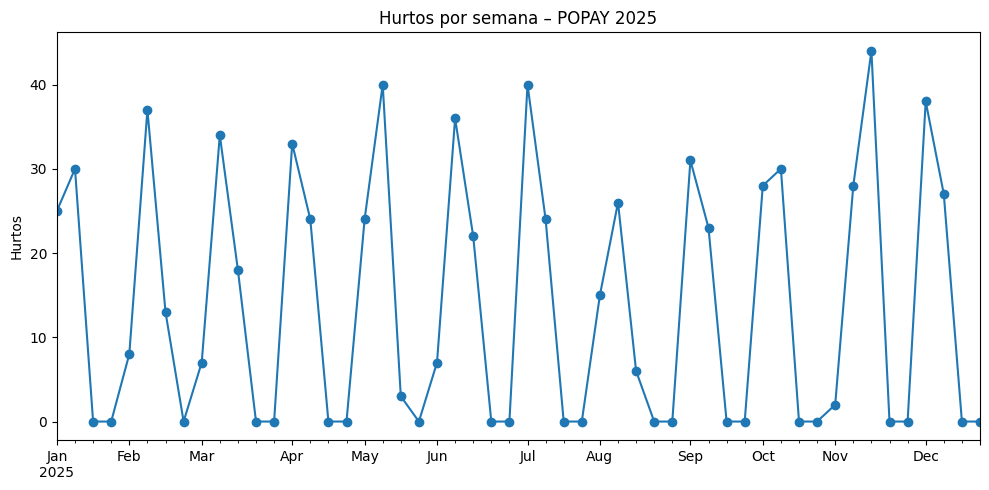

In [ ]:
# ---- Configuración del ejemplo ----
MUNICIPIO = "POPAY"      # texto que contenga el nombre (los nombres traen sufijos como "(CT)")
TIPO = None              # p. ej. "RESIDENCIAS" para un solo tipo de hurto; None = todos
ANIO = 2025              # año que se modela (λ)
ANIO_HIST = ANIO - 1     # año "histórico" para la prueba de hipótesis (λ₀)
UMBRAL = 15              # umbral de alerta del informe (pregunta 8)

col_mun = next(c for c in df.columns if "municipio" in c.lower())
col_tipo = next((c for c in df.columns if "tipo" in c.lower()), None)

base = df[df[col_mun].str.contains(MUNICIPIO, na=False) & df[COL_FECHA].notna()]
if TIPO and col_tipo:
    base = base[base[col_tipo].str.contains(TIPO, na=False)]

def conteo_semanal(datos, anio):
    """Hurtos por semana (lunes a domingo) del año dado, con semanas vacías = 0."""
    d = datos[datos[COL_FECHA].dt.year == anio]
    semanas = pd.date_range(f"{anio}-01-01", f"{anio}-12-31", freq="W-SUN")
    return (d.set_index(COL_FECHA)["cantidad"].resample("W-SUN").sum()
              .reindex(semanas, fill_value=0).astype(int))

X = conteo_semanal(base, ANIO)
n = len(X)
lam = X.mean()
s2 = X.var(ddof=1)

print(f"Municipio: {base[col_mun].iloc[0] if not base.empty else MUNICIPIO} | Tipo: {TIPO or 'TODOS'} | Año {ANIO}")
print(f"Semanas: {n} | Total hechos: {X.sum():,}")
print(f"λ (media semanal) = {lam:.2f} | s² = {s2:.2f} | s²/x̄ = {s2/lam:.2f}")
if s2 / lam > 1.5:
    print("⚠️ Sobredispersión: la varianza es bastante mayor que la media; Poisson subestima los extremos (ver conclusiones del informe).")
X.plot(marker="o", title=f"Hurtos por semana – {MUNICIPIO} {ANIO}", ylabel="Hurtos"); plt.tight_layout(); plt.show()

### 9.1 Probabilidades de los eventos A, B, C (Tabla I del informe, con λ real)

In [ ]:
P = stats.poisson(lam)

# Umbral de alerta "raro": menor k con P(X ≥ k) < 0,05
k_alerta = int(P.isf(0.05)) + 1
while P.sf(k_alerta - 1) >= 0.05:
    k_alerta += 1

tabla = pd.DataFrame({
    "Evento": ["X = 10", "X ≤ 8", "9 ≤ X ≤ 14", f"X ≥ {UMBRAL}", f"X ≥ {k_alerta} (alerta 5 %)"],
    "Probabilidad": [P.pmf(10), P.cdf(8), P.cdf(14) - P.cdf(8), P.sf(UMBRAL - 1), P.sf(k_alerta - 1)],
})
tabla["Probabilidad"] = tabla["Probabilidad"].round(4)
display(tabla)

# Proporción observada de semanas que superan el umbral vs la del modelo
print(f"Semanas reales con X ≥ {UMBRAL}: {(X >= UMBRAL).mean():.3f}  |  Modelo: {P.sf(UMBRAL-1):.3f}")

,Evento,Probabilidad
0,X = 10,0.0681
1,X ≤ 8,0.0650
2,9 ≤ X ≤ 14,0.5156
3,X ≥ 15,0.4194
4,X ≥ 21 (alerta 5 %),0.0452


Semanas reales con X ≥ 15: 0.442  |  Modelo: 0.419


### 9.2 Observado vs Poisson (Fig. 1 con datos reales)

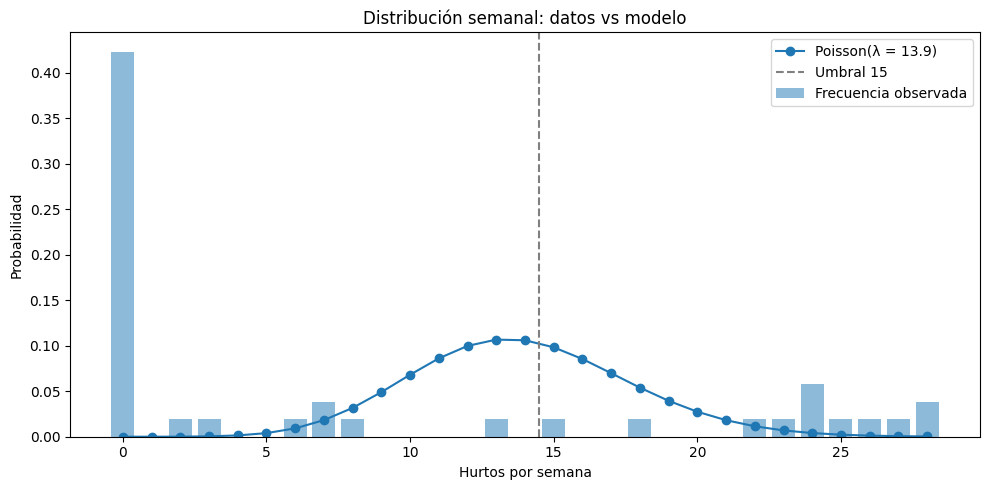

In [ ]:
ks = np.arange(max(0, int(lam - 4*np.sqrt(lam))), int(lam + 4*np.sqrt(lam)) + 1)
obs = X.value_counts(normalize=True).reindex(ks, fill_value=0)

fig, ax = plt.subplots()
ax.bar(ks, obs.values, alpha=0.5, label="Frecuencia observada")
ax.plot(ks, P.pmf(ks), "o-", label=f"Poisson(λ = {lam:.1f})")
ax.axvline(UMBRAL - 0.5, ls="--", c="gray", label=f"Umbral {UMBRAL}")
ax.set_xlabel("Hurtos por semana"); ax.set_ylabel("Probabilidad"); ax.legend()
ax.set_title("Distribución semanal: datos vs modelo"); plt.tight_layout(); plt.show()

### 9.3 Suma de 7 semanas: S₇ ~ Poisson(7λ) y aproximación normal (TLC)

In [ ]:
lam7 = 7 * lam
c = int(np.ceil(lam7 + 2 * np.sqrt(lam7)))       # umbral ≈ media + 2σ (en el informe: 100 con λ₇ = 84)
exacta = stats.poisson(lam7).sf(c)               # P(S₇ > c)
z = (c + 0.5 - lam7) / np.sqrt(lam7)             # corrección de continuidad
aprox = stats.norm.sf(z)
print(f"S₇ ~ Poisson({lam7:.1f}) | P(S₇ > {c}) exacta = {exacta:.4f} | normal = {aprox:.4f} | diferencia = {abs(exacta-aprox):.4f}")

### 9.4 Prueba de hipótesis sobre la tasa (pregunta 10)

H₀: λ = λ₀ (media semanal del año histórico) vs H₁: λ ≠ λ₀, α = 0,05.
z = (x̄ − λ₀)/√(λ₀/n) e IC 95 %: x̄ ± 1,96·√(x̄/n).

In [ ]:
X_hist = conteo_semanal(base, ANIO_HIST)
lam0 = X_hist.mean()
z = (lam - lam0) / np.sqrt(lam0 / n)
p_valor = 2 * stats.norm.sf(abs(z))
ic = (lam - 1.96*np.sqrt(lam/n), lam + 1.96*np.sqrt(lam/n))

print(f"λ₀ ({ANIO_HIST}) = {lam0:.2f} | x̄ ({ANIO}) = {lam:.2f} | n = {n}")
print(f"z = {z:.2f} | valor-p = {p_valor:.4f}")
print(f"IC 95 %: [{ic[0]:.2f}; {ic[1]:.2f}]")
print("Se rechaza H₀: la tasa cambió." if p_valor < 0.05 else "No se rechaza H₀: no hay evidencia de cambio en la tasa.")

### 9.5 Bondad de ajuste χ² (¿sirve Poisson para estos datos?)

In [ ]:
# Se agrupan valores para que cada clase tenga frecuencia esperada ≥ 5
lo, hi = int(P.ppf(0.05)), int(P.ppf(0.95))
bordes = list(range(lo, hi + 1))
obs_f = [(X < lo).sum()] + [(X == k).sum() for k in bordes] + [(X > hi).sum()]
esp_p = [P.cdf(lo - 1)] + [P.pmf(k) for k in bordes] + [P.sf(hi)]
esp_f = np.array(esp_p) * n

# Fusionar clases con esperada < 5
o, e = [], []
acc_o = acc_e = 0
for fo, fe in zip(obs_f, esp_f):
    acc_o += fo; acc_e += fe
    if acc_e >= 5:
        o.append(acc_o); e.append(acc_e); acc_o = acc_e = 0
if acc_e > 0 and e:
    o[-1] += acc_o; e[-1] += acc_e
e = np.array(e) * (n / np.sum(e))   # ajusta por redondeo

chi2, p = stats.chisquare(o, e, ddof=1)   # ddof=1 porque λ se estimó de los datos
print(f"Clases: {len(o)} | χ² = {chi2:.2f} | valor-p = {p:.4f}")
print("El ajuste Poisson es aceptable." if p >= 0.05 else "Los datos NO se ajustan bien a Poisson (probable sobredispersión).")

## 8. Exportar

In [ ]:
os.makedirs(CARPETA_LOCAL, exist_ok=True)
ruta_csv = f"{CARPETA_LOCAL}/hurtos_colombia_completo.csv"
ruta_parquet = f"{CARPETA_LOCAL}/hurtos_colombia_completo.parquet"

df.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
df.to_parquet(ruta_parquet, index=False)
print("Guardado:", ruta_csv, "|", ruta_parquet)

if GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(CARPETA_DRIVE, exist_ok=True)
    for r in (ruta_csv, ruta_parquet):
        os.system(f'cp "{r}" "{CARPETA_DRIVE}/"')
    print("Copiado a Drive:", CARPETA_DRIVE)

Guardado: /content/datos/hurtos_colombia_completo.csv | /content/datos/hurtos_colombia_completo.parquet


In [ ]:
# Descargar el CSV a tu computador
from google.colab import files
files.download(ruta_csv)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Próximos pasos
- Cambia `DESDE = "2026-01-01"` en la sección 2 para quedarte solo con 2026.
- Prueba otros conjuntos de la Policía en datos.gov.co: violencia intrafamiliar (`vuyt-mqpw`), delitos sexuales (`fpe5-yrmw`), lesiones personales (`72sg-cybi`), recuperación de vehículos (`dhy3-732k`), capturas (`3jdh-nmwu`). Solo añade el ID a `RECURSOS`.
- Para modelos: agrupa por municipio y mes, y prueba regresión o series de tiempo (Prophet, statsmodels).